# 03 · Model Training & Evaluation
**Project 1: Rossmann Store Sales Prediction**

## Objective
- Baseline: `StandardScaler` then `LinearRegression`, scored with RMSE, MAE, R²
- `XGBRegressor(n_estimators=200)` and a comparison with the baseline
- Cross-validate both models (5 folds), report mean and std of RMSE
- Plot actual vs predicted and the residual distribution, and look for patterns in the errors

> **Data:** the real Rossmann Store Sales data (`train.csv`, `store.csv`). The files are not in this repo
> (competition data rules). The notebook uses `data/` if the files are there, otherwise it downloads a public copy.
> See `data/README.md`.

## Project setup

In [1]:
import sys
from pathlib import Path

# Project folders (works from notebooks/ or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIG = OUT / "modeling"
FIG.mkdir(parents=True, exist_ok=True)

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer
from xgboost import XGBRegressor

from features import add_date_features, add_lag_features, merge_store_info

## The plan (from notebooks 01 and 02)
- Predict daily `Sales` per store, **6 weeks ahead**. Main metric: **RMSPE** (relative error). RMSE and MAE are in sales units, so big stores dominate them
- Features from notebook 02: date features, store info, `lag_42` and `lag_49` (the only lags known 6 weeks ahead), and store history (each store's average sales)
- Not used: `Customers` (leak), `lag_1` and `lag_7` (not known at forecast time)
- Baselines from earlier days: **RMSPE 0.147** (store + weekday + promo average) and 0.148 (a quick gradient boosting model)

In [3]:
BASE = "https://raw.githubusercontent.com/RPI-DATA/tutorials-intro/master/rossmann-store-sales/rossmann-store-sales/"

def load(name):
    local = DATA / name
    return pd.read_csv(local if local.exists() else BASE + name, low_memory=False)

train = load("train.csv")
store = load("store.csv")
train["Date"] = pd.to_datetime(train["Date"])
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)

feat = add_date_features(train)
feat = add_lag_features(feat, lags=(42, 49))
feat = merge_store_info(feat, store)
feat["state_holiday"] = feat["state_holiday"].astype(str)

# Open days only (as in notebooks 01 and 02)
data = feat[(feat["Open"] == 1) & (feat["Sales"] > 0)].reset_index(drop=True)
print("Modeling rows:", len(data))

Modeling rows: 844338


## 1. Model code, saved to `modeling.py`
Store history features (each store's average sales) use the **target**, so they must be learned from the training part of each fold only.
A small custom transformer does that safely inside the pipeline.

The functions live in `src/modeling.py` (printed below), so every notebook uses exactly the same code.

In [4]:
print((ROOT / "src" / "modeling.py").read_text())

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC = ["DayOfWeek", "Promo", "SchoolHoliday", "year", "day", "week_of_year", "is_weekend",
           "is_month_end", "CompetitionDistance", "Promo2", "lag_42", "lag_49",
           "store_mean", "store_dow_mean"]
CATEGORICAL = ["store_type", "assortment", "state_holiday"]
INPUT_COLUMNS = [c for c in NUMERIC if c not in ("store_mean", "store_dow_mean")] + CATEGORICAL + ["Store", "day_of_week"]


class StoreHistory(BaseEstimator, TransformerMixin):
    """Adds each store's average target (and store + weekday average), learned from the data it is fitted on."""

    def fit(self, X, y

In [5]:
from modeling import make_model, metrics, rmspe, INPUT_COLUMNS, GroupMeanBaseline

X = data[INPUT_COLUMNS]
y = data["Sales"]
print(X.shape)

(844338, 17)


## 2. Time-based cross-validation: 5 windows of 42 days
Each fold **trains on everything before a window** and **tests on the next 42 days**, like a real 6-week forecast.
The last window (2015-06-20 to 2015-07-31) is the same validation period as notebooks 01 and 02.

In [6]:
last_day = data["Date"].max()
starts = [last_day - pd.Timedelta(days=41 + 42 * i) for i in range(5)][::-1]

splits = []
for start in starts:
    end = start + pd.Timedelta(days=41)
    train_idx = np.where(data["Date"] < start)[0]
    test_idx = np.where((data["Date"] >= start) & (data["Date"] <= end))[0]
    splits.append((train_idx, test_idx))
    print(f"test {start.date()} to {end.date()} | train rows {len(train_idx):7d} | test rows {len(test_idx):6d}")

test 2015-01-03 to 2015-02-13 | train rows  649442 | test rows  39923
test 2015-02-14 to 2015-03-27 | train rows  689365 | test rows  40175
test 2015-03-28 to 2015-05-08 | train rows  729540 | test rows  37044
test 2015-05-09 to 2015-06-19 | train rows  766584 | test rows  37472
test 2015-06-20 to 2015-07-31 | train rows  804056 | test rows  40282


In [7]:
def backtest(make):
    rows, last_pred, last_model = [], None, None
    for i, (tr, te) in enumerate(splits, start=1):
        model = make().fit(X.iloc[tr], y.iloc[tr])
        pred = model.predict(X.iloc[te])
        rows.append({"fold": i, **metrics(y.iloc[te], pred)})
        if i == len(splits):
            last_pred, last_model = pred, model
    return pd.DataFrame(rows).set_index("fold"), last_pred, last_model

candidates = {
    "Store+weekday+promo average": lambda: GroupMeanBaseline(),
    "Linear Regression": lambda: make_model(LinearRegression()),
    "XGBoost (200 trees)": lambda: make_model(XGBRegressor(n_estimators=200, random_state=42)),
    "XGBoost (200 trees, log target)": lambda: make_model(XGBRegressor(n_estimators=200, random_state=42), log_target=True),
}

fold_metrics, last_preds, last_models = {}, {}, {}
for name, make in candidates.items():
    fold_metrics[name], last_preds[name], last_models[name] = backtest(make)
    print("done:", name)

done: Store+weekday+promo average


done: Linear Regression


done: XGBoost (200 trees)


done: XGBoost (200 trees, log target)


## 3. Baseline: StandardScaler then LinearRegression (last 42 days)

In [8]:
hold = splits[-1][1]
y_hold = y.iloc[hold]

base = metrics(y_hold, last_preds["Linear Regression"])
print("Linear baseline, last 42 days")
print("RMSE :", round(base["rmse"]))
print("MAE  :", round(base["mae"]))
print("R2   :", round(base["r2"], 3))
print("RMSPE:", round(base["rmspe"], 3))

Linear baseline, last 42 days
RMSE : 1199
MAE  : 866
R2   : 0.846
RMSPE: 0.184


## 4. XGBoost vs the baseline (last 42 days)

In [9]:
print("Last 42 days:")
for name in candidates:
    m = metrics(y_hold, last_preds[name])
    print(f"{name:32s} RMSE {m['rmse']:6.0f} | R2 {m['r2']:.3f} | RMSPE {m['rmspe']:.3f}")

lin = fold_metrics["Linear Regression"].loc[5, "rmse"]
xgb = fold_metrics["XGBoost (200 trees)"].loc[5, "rmse"]
print(f"XGBoost RMSE is {(1 - xgb / lin) * 100:.1f}% lower than the baseline")

Last 42 days:
Store+weekday+promo average      RMSE   1109 | R2 0.868 | RMSPE 0.147
Linear Regression                RMSE   1199 | R2 0.846 | RMSPE 0.184
XGBoost (200 trees)              RMSE   1054 | R2 0.881 | RMSPE 0.154
XGBoost (200 trees, log target)  RMSE   1167 | R2 0.854 | RMSPE 0.168
XGBoost RMSE is 12.1% lower than the baseline


## 5. Cross-validation: mean and std across the 5 windows

In [10]:
summary = pd.DataFrame({
    name: {
        "RMSE mean": fm["rmse"].mean(), "RMSE std": fm["rmse"].std(),
        "RMSPE mean": fm["rmspe"].mean(), "RMSPE std": fm["rmspe"].std(),
    }
    for name, fm in fold_metrics.items()
}).T
print(summary.round(3).to_string())

                                 RMSE mean  RMSE std  RMSPE mean  RMSPE std
Store+weekday+promo average       1127.234   219.544       0.170      0.020
Linear Regression                 1199.521   161.140       0.193      0.019
XGBoost (200 trees)               1042.596   149.380       0.161      0.017
XGBoost (200 trees, log target)   1052.559   152.189       0.158      0.016


      Store+weekday+promo average  Linear Regression  XGBoost (200 trees)  XGBoost (200 trees, log target)
fold                                                                                                      
1                           0.184              0.218                0.176                            0.160
2                           0.194              0.210                0.177                            0.176
3                           0.171              0.174                0.161                            0.152
4                           0.153              0.181                0.136                            0.133
5                           0.147              0.184                0.154                            0.168


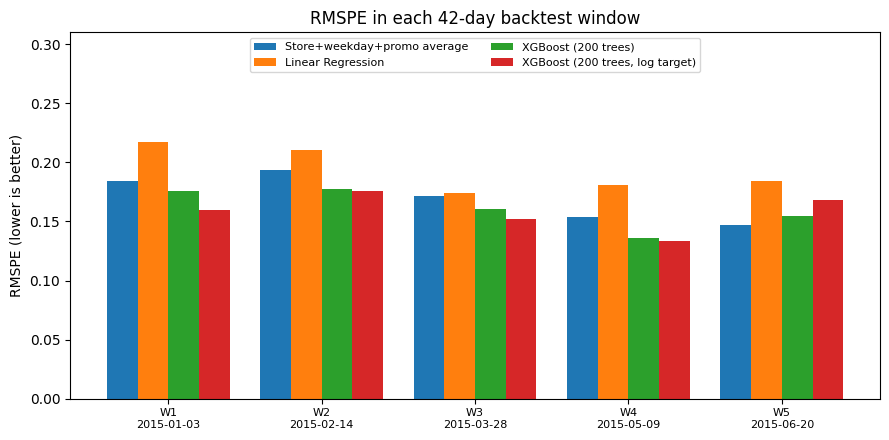

In [11]:
print(pd.DataFrame({n: fm["rmspe"] for n, fm in fold_metrics.items()}).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.2
folds = np.arange(1, 6)
for i, (name, fm) in enumerate(fold_metrics.items()):
    ax.bar(folds + (i - 1.5) * width, fm["rmspe"], width, label=name)
ax.set_xticks(folds)
ax.set_xticklabels(["W" + str(i) + "\n" + str(starts[i - 1].date()) for i in folds], fontsize=8)
ax.set_ylabel("RMSPE (lower is better)")
ax.set_ylim(0, 0.31)
ax.set_title("RMSPE in each 42-day backtest window")
ax.legend(fontsize=8, ncol=2, loc="upper center")
plt.tight_layout()
plt.savefig(FIG / "fold_rmspe_comparison.png", dpi=150)
plt.show()

## 6. Why not plain shuffled 5-fold?
`KFold(5, shuffle=True)` mixes all dates together, so the model is tested on days that sit **between** days it trained on. That is not a forecast.
Same model, two ways of testing it. They also cover different dates (shuffled folds use the whole history, the windows use only 2015), so this is not a perfectly clean comparison.

In [12]:
rmspe_scorer = make_scorer(rmspe, greater_is_better=False)
shuffled = cross_validate(
    candidates["XGBoost (200 trees)"](), X, y,
    cv=KFold(5, shuffle=True, random_state=42),
    scoring={"rmse": "neg_root_mean_squared_error", "rmspe": rmspe_scorer},
)
back = fold_metrics["XGBoost (200 trees)"]

print("XGBoost (200 trees)        RMSE mean | RMSPE mean")
print(f"Shuffled 5-fold (leaky)     {-shuffled['test_rmse'].mean():8.0f} | {-shuffled['test_rmspe'].mean():.3f}")
print(f"Time-ordered 5 windows      {back['rmse'].mean():8.0f} | {back['rmspe'].mean():.3f}")

XGBoost (200 trees)        RMSE mean | RMSPE mean
Shuffled 5-fold (leaky)          775 | 0.179
Time-ordered 5 windows          1043 | 0.161


## 7. Actual vs predicted, and the residuals (last 42 days)

XGBoost version used for the plots: XGBoost (200 trees, log target)


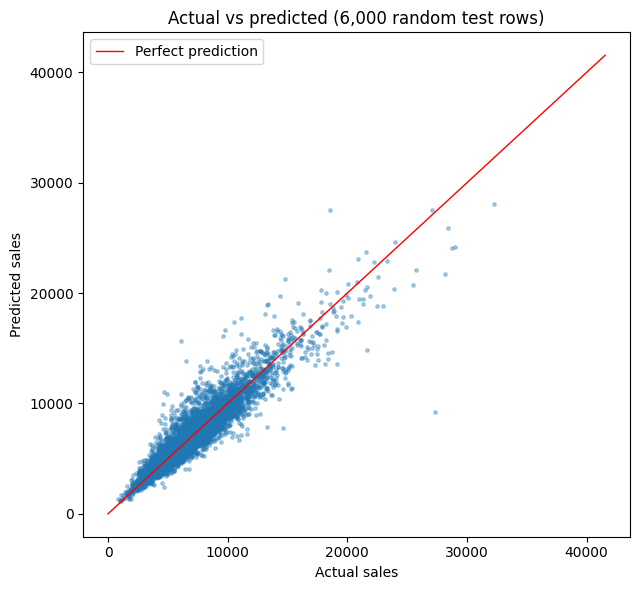

In [13]:
best_name = min(
    [n for n in candidates if n.startswith("XGBoost")],
    key=lambda n: fold_metrics[n]["rmspe"].mean(),
)
print("XGBoost version used for the plots:", best_name)

pred = last_preds[best_name]
actual = y_hold.to_numpy()
residual = actual - pred
pct_error = residual / actual

rng = np.random.default_rng(0)
pick = rng.choice(len(actual), 6000, replace=False)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(actual[pick], pred[pick], s=6, alpha=0.35, color="#1f77b4")
top = max(actual.max(), pred.max())
ax.plot([0, top], [0, top], color="red", linewidth=1, label="Perfect prediction")
ax.set_xlabel("Actual sales")
ax.set_ylabel("Predicted sales")
ax.set_title("Actual vs predicted (6,000 random test rows)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "actual_vs_predicted.png", dpi=150)
plt.show()

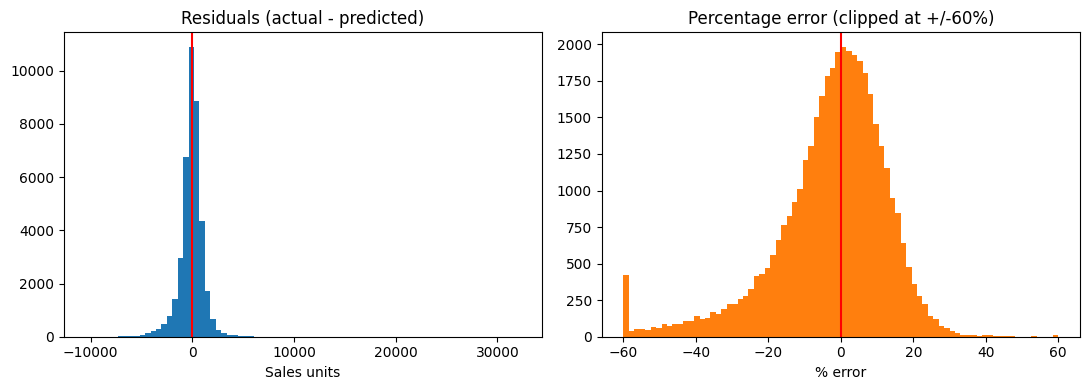

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(residual, bins=80, color="#1f77b4")
ax[0].axvline(0, color="red")
ax[0].set_title("Residuals (actual - predicted)")
ax[0].set_xlabel("Sales units")
ax[1].hist(np.clip(pct_error, -0.6, 0.6) * 100, bins=80, color="#ff7f0e")
ax[1].axvline(0, color="red")
ax[1].set_title("Percentage error (clipped at +/-60%)")
ax[1].set_xlabel("% error")
plt.tight_layout()
plt.savefig(FIG / "residual_distribution.png", dpi=150)
plt.show()

In [15]:
print("Residual summary (actual - predicted):")
print("Mean residual (bias):", round(residual.mean(), 1), "| median:", round(np.median(residual), 1))
print("Within +/-10% of actual:", round((np.abs(pct_error) <= 0.10).mean() * 100, 1), "% of rows")
print("Within +/-20% of actual:", round((np.abs(pct_error) <= 0.20).mean() * 100, 1), "% of rows")
print("Worst 1% of rows have |error| above:", round(np.quantile(np.abs(pct_error), 0.99) * 100), "%")

Residual summary (actual - predicted):
Mean residual (bias): -99.3 | median: -28.4
Within +/-10% of actual: 57.3 % of rows
Within +/-20% of actual: 85.2 % of rows
Worst 1% of rows have |error| above: 60 %


## 8. Patterns in the errors

In [16]:
test_rows = data.iloc[hold].copy()
test_rows["pct_sq"] = pct_error ** 2
store_size = data[data["Date"] < starts[-1]].groupby("Store")["Sales"].mean()
test_rows["store_size"] = pd.qcut(test_rows["Store"].map(store_size), 4, labels=["small", "mid-small", "mid-large", "large"])

def group_rmspe(col):
    return test_rows.groupby(col, observed=True)["pct_sq"].mean().pow(0.5).round(3)

for col in ["DayOfWeek", "Promo", "store_type", "store_size"]:
    print(col, group_rmspe(col).to_dict())

DayOfWeek {1: 0.125, 2: 0.129, 3: 0.151, 4: 0.232, 5: 0.14, 6: 0.204, 7: 0.138}
Promo {0: 0.157, 1: 0.182}
store_type {'a': 0.165, 'b': 0.114, 'c': 0.166, 'd': 0.176}
store_size {'small': 0.177, 'mid-small': 0.177, 'mid-large': 0.157, 'large': 0.16}


In [17]:
by_date = test_rows.groupby("Date")["pct_sq"].mean().pow(0.5).sort_values(ascending=False)
worst = by_date.head(5)
for date, value in worst.items():
    day = test_rows[test_rows["Date"] == date]
    print(date.date(), date.day_name()[:3], "RMSPE", round(value, 3), "| rows", len(day),
          "| average % error", round(day["pct_sq"].pow(0.5).mean() * 100), "%")
print("Typical day RMSPE (median over days):", round(by_date.median(), 3))

2015-07-02 Thu RMSPE 0.492 | rows 1114 | average % error 44 %
2015-07-04 Sat RMSPE 0.401 | rows 1114 | average % error 36 %
2015-07-01 Wed RMSPE 0.267 | rows 1115 | average % error 21 %
2015-07-19 Sun RMSPE 0.193 | rows 32 | average % error 16 %
2015-07-07 Tue RMSPE 0.192 | rows 1114 | average % error 15 %
Typical day RMSPE (median over days): 0.123


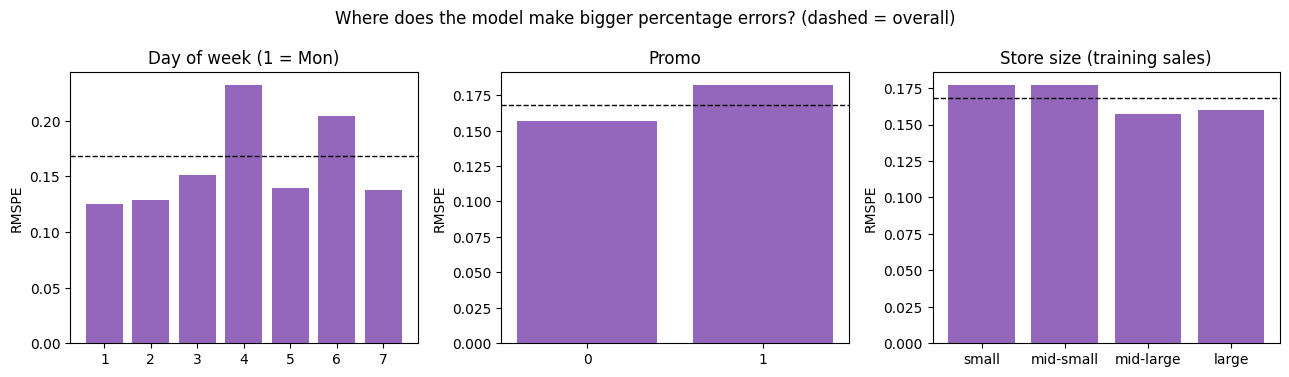

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col, title in zip(ax, ["DayOfWeek", "Promo", "store_size"], ["Day of week (1 = Mon)", "Promo", "Store size (training sales)"]):
    g = group_rmspe(col)
    a.bar([str(i) for i in g.index], g.values, color="#9467bd")
    a.axhline(rmspe(actual, pred), color="black", linestyle="--", linewidth=1)
    a.set_title(title)
    a.set_ylabel("RMSPE")
fig.suptitle("Where does the model make bigger percentage errors? (dashed = overall)")
plt.tight_layout()
plt.savefig(FIG / "error_by_group.png", dpi=150)
plt.show()

## Practice Exercise
Which features does XGBoost rely on most? Plot the top 10 `feature_importances_`.

store_dow_mean    0.597
Promo             0.211
is_month_end      0.031
DayOfWeek         0.025
day               0.018
week_of_year      0.018
store_mean        0.012
lag_42            0.011
assortment_b      0.009
year              0.009


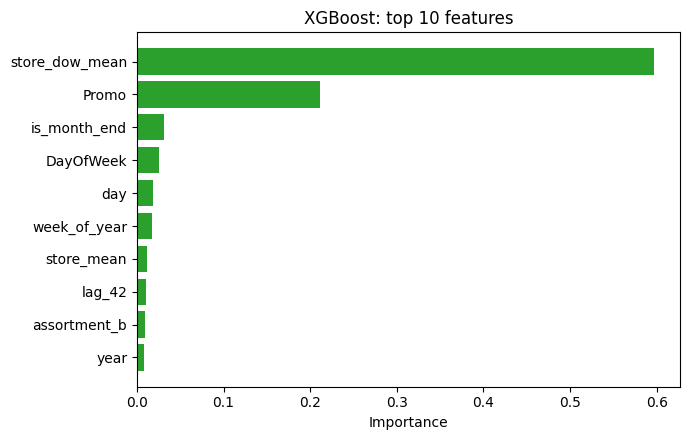

In [19]:
fitted = last_models[best_name]
pipe = fitted.regressor_ if hasattr(fitted, "regressor_") else fitted
names = pipe.named_steps["prep"].get_feature_names_out()
importance = pd.Series(pipe.named_steps["model"].feature_importances_, index=[n.split("__")[1] for n in names])
top10 = importance.sort_values(ascending=False).head(10)
print(top10.round(3).to_string())

plt.figure(figsize=(7, 4.5))
plt.barh(top10.index[::-1], top10.values[::-1], color="#2ca02c")
plt.xlabel("Importance")
plt.title("XGBoost: top 10 features")
plt.tight_layout()
plt.savefig(FIG / "feature_importance_xgboost.png", dpi=150)
plt.show()

## Mini Challenge
Try `max_depth` 4, 6, and 8 on the last window. Does depth change the RMSPE? (Choosing a setting on the test window makes that score a bit optimistic, so treat this as a hint, not a final tuning.)

In [20]:
use_log = "log" in best_name
tr, te = splits[-1]
for depth in [4, 6, 8]:
    m = make_model(XGBRegressor(n_estimators=200, max_depth=depth, random_state=42), log_target=use_log)
    m.fit(X.iloc[tr], y.iloc[tr])
    print("max_depth", depth, "-> RMSPE", round(rmspe(y.iloc[te], m.predict(X.iloc[te])), 3))

max_depth 4 -> RMSPE 0.146


max_depth 6 -> RMSPE 0.168


max_depth 8 -> RMSPE 0.167


## Save the backtest results (used by the final figures)

In [21]:
results_dir = OUT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

backtest_table = pd.concat(fold_metrics, names=["model"]).reset_index()
backtest_table["window_start"] = backtest_table["fold"].map(lambda i: str(starts[i - 1].date()))
backtest_table.to_csv(results_dir / "backtest_metrics.csv", index=False)
print(backtest_table.round(3).head(3).to_string(index=False))

                      model  fold     rmse     mae    r2  rmspe window_start
Store+weekday+promo average     1 1030.673 721.376 0.869  0.184   2015-01-03
Store+weekday+promo average     2  902.068 601.194 0.896  0.194   2015-02-14
Store+weekday+promo average     3 1490.424 988.332 0.801  0.171   2015-03-28


## Summary
- A Linear Regression baseline and an XGBoost model, both in one pipeline with fold-safe store history
- Tested with a time-ordered backtest (5 windows of 42 days), the honest version of cv=5
- Shuffled cross-validation gave a different answer than the time-ordered windows (better RMSE, worse RMSPE), so it is not a trustworthy stand-in for a real forecast
- Residual plots and error tables show where the model is weaker
- Next: notebook 04, project visuals, README, and GitHub